# Module 02: A Box Model Carbon Assignment

### 1. Introduction

In the accompanying notebook [mod02-CarbonModel1.ipynb](./mod02-CarbonModel1.ipynb) and in class we developed a relatively simple model of global carbon balance that assumed that tracked carbon in the atmosphere and biosphere. The system of equations we developed to describe this system are shown below,

$$
\begin{align*}
\frac{dM_1}{dt} &= F_{21} - F_{12}\\
&= k_{21}M_2 - k_{12}M_1
\end{align*}
$$

and,

$$
\begin{align*}
\frac{dM_2}{dt} &= F_{12} - F_{21}\\
&= k_{12}M_1 - k_{21}M_2
\end{align*}
$$

where $M_1$ is the mass of carbon in the atmosphere (GtC), $M_2$ is the mass of carbon in the biosphere (GtC), $F_{12}$ is the flux of carbon from the atmosphere to the biosphere due to photosynthesis (GtC/yr), and $F_{21}$ is the flux of carbon from the biosphere to the atmosphere due to decay and respiration (GtC/yr).

In that notebook we develop a numerical model to describe that system, run it for given initial conditions and with no external inputs of carbon (we call this an "unforced" scenario) and compare it to the analytical solution. We observed that as the time step increased, we departed further from the analytical solution. 

In this assignment you will take your model one step more realistic by ensuring that the photosynthetic flux depends on both the amount of carbon in the atmosphere and in the biosphere. Then you will examine the impact of anthropogenic emissions from 1751-2008 on the biosphere and atmosphere, and how alternative future scenarios of emissions mitigation affect your system. 

The code cell below contains a couple of new commands and some file names that you will need in this assignment. You will need all of these commands, _but not necessarily

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# historical_emissions_file = 'AnthropogenicEmissions.1751_2008.csv'
# data = np.loadtxt(historical_emissions_file, delimiter=',', skiprows=1)
# # Read this documentation to understand what this command does:
# #    https://numpy.org/doc/stable/reference/generated/numpy.loadtxt.html
# year = data[:, 0]
# cflux = data[:, 1]

# #cflux_t = np.interp(t, year, cflux)
# # Read this documentation to understand what this command does: 
# #    https://numpy.org/doc/stable/reference/generated/numpy.interp.html

# np.diff(M1)
# # Read this documentation to understand what this command does:
# #    https://numpy.org/doc/stable/reference/generated/numpy.diff.html

# Problem A

In [2]:
#daily time array for 100 years
#t = np.arange(0, 100 + 1/365, 1/365)

#DEFIINE INITIAL CONDITIONS AND PARAMETERS
#mass of carbon in atm
M1i = 1100.0
#mass of carbon in land
M2i = 300.0

k12 = 0.0003 
k21 = 0.1

#initial time
ti = 0.0
#final time
tf = 365.0
#one day time step
dt = 1

#interpolate carbon flux data to daily time array
# cflux_daily = np.interp(t, year, cflux)

# print(cflux_daily[:10])
# print(year)

#time array, daily time step
t = np.arange(ti,tf+dt,dt)

#number of time steps
Nt = t.size

print('t has '+str(Nt)+' time steps')

t has 366 time steps


In [3]:
#initialize arrays to hold mass of carbon in atm and biosphere
M1 = np.zeros((Nt,))
M2 = np.zeros((Nt,))

#for each time step
for i in np.arange(Nt):
    #if time step is zero, set initial mass of carbon in atm and biosphere
    if (i==0):

        M1[i] = M1i
        M2[i] = M2i

    #if time step is not zero, calculate mass of carbon in atm and biosphere using finite difference method    
    else:
        #dM/dt = k21*M2 - k12*M1
        dM1dt = k21*M2[i-1] - k12*M1[i-1]
        dM2dt = k12*M1[i-1] - k21*M2[i-1]

        #update mass of carbon in atm and biosphere
        M1[i] = M1[i-1] + dM1dt*dt
        M2[i] = M2[i-1] + dM2dt*dt

print('The final mass of carbon in the atmosphere is '+str(M1[-1])+' Gt')
print('The final mass of carbon in the biosphere is '+str(M2[-1])+' Gt')

The final mass of carbon in the atmosphere is 1395.81256231306 Gt
The final mass of carbon in the biosphere is 4.187437686939184 Gt


In [4]:
plt.rcParams.update({
    "font.size": 12,
    "font.weight": "bold",
    "axes.labelweight": "bold",
    "axes.titleweight": "bold",
    "axes.titlesize": 14,
    "legend.fontsize": 11,
})

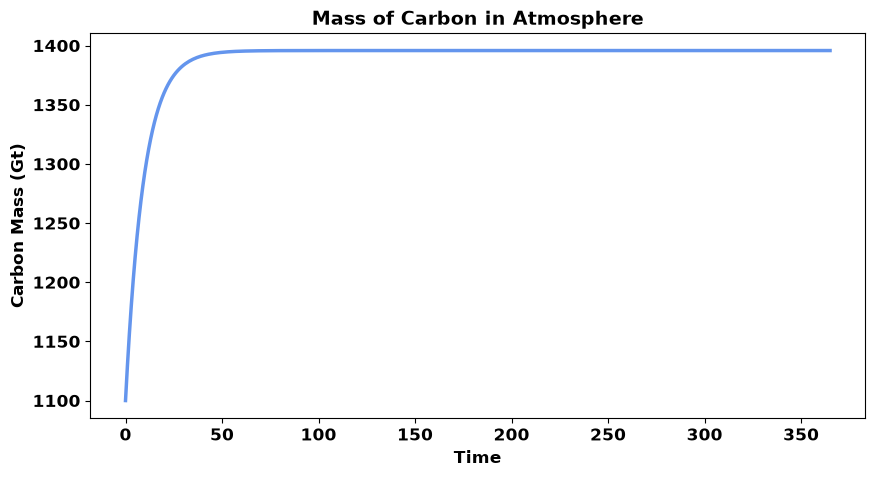

In [5]:
#plot carbon in atmosphere
plt.figure(figsize=(10,5))
plt.plot(t, M1, color='cornflowerblue', linewidth=2.5)
plt.xlabel('Time')
plt.ylabel('Carbon Mass (Gt)')
plt.title('Mass of Carbon in Atmosphere')
plt.show()

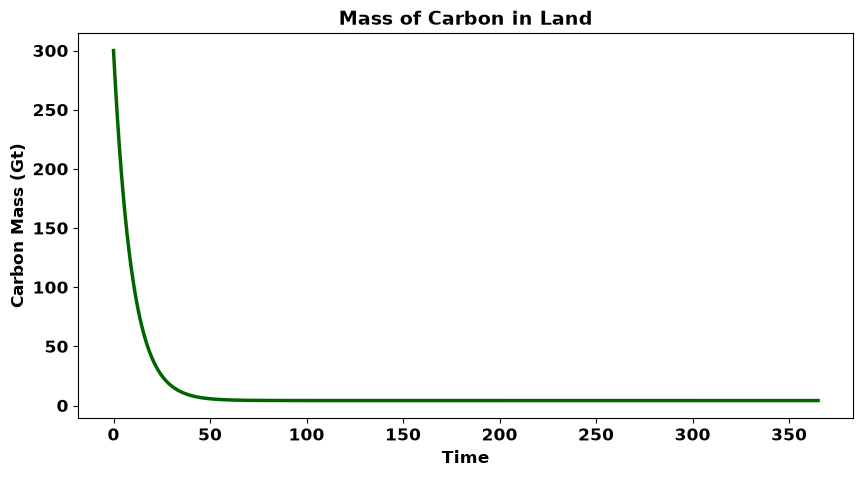

In [6]:
#plot carbon in biosphere
plt.figure(figsize=(10,5))
plt.plot(t, M2, color='darkgreen', linewidth=2.5)
plt.xlabel('Time')
plt.ylabel('Carbon Mass (Gt)')
plt.title('Mass of Carbon in Land')
plt.show()

# Problem B

In [7]:
#import data
historical_emissions_file = '/Users/lindsaysummers/Documents/Geos518/Earth-and-Environmental-Systems-Modeling/mod02_Finite-Difference-Box-Models/AnthropogenicEmissions.1751_2008.csv'
data = np.loadtxt(historical_emissions_file, delimiter=',', skiprows=1)

#years of data
year = data[:, 0]

#carbon flux data
cflux = data[:, 1]

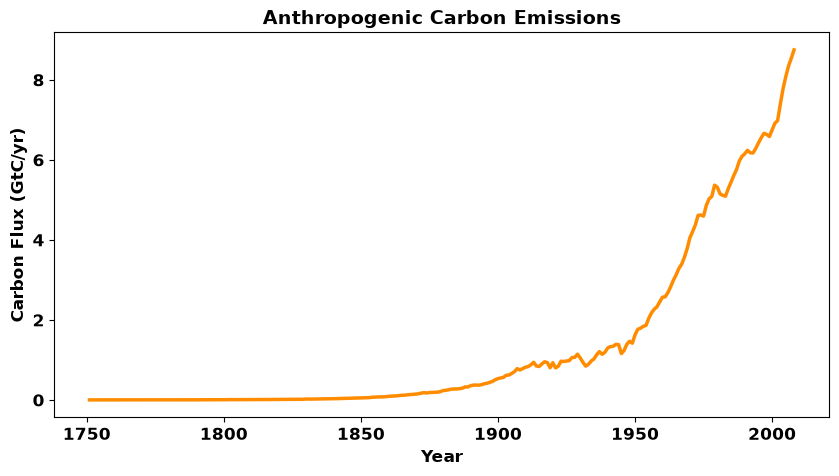

In [8]:
#plot anthropogenic emissions
plt.figure(figsize=(10,5))
plt.plot(year, cflux, color='darkorange', linewidth=2.5)
plt.xlabel('Year')
plt.ylabel('Carbon Flux (GtC/yr)')
plt.title('Anthropogenic Carbon Emissions') 
plt.show()

In [9]:
# Starting from the final conditions in Part A, simulate the response to historical anthropogenic emissions.

# Final conditions from Problem A become the initial conditions for this run
M1i = M1[-1]
M2i = M2[-1]

# Make a time array for 1751 to 2008 using annual time steps
ti = 1751.0
tf = 2008.0
dt = 1.0
t = np.arange(ti, tf + dt, dt)
Nt = t.size

# Interpolate the annual emissions onto the model time array
cflux_t = np.interp(t, year, cflux)

# Reinitialize the state arrays for this new simulation window
M1 = np.zeros((Nt,))
M2 = np.zeros((Nt,))

for i in np.arange(Nt):
    #if time step is zero, set initial mass of carbon in atm and biosphere
    if (i==0):

        M1[i] = M1i
        M2[i] = M2i
    else:
        dM1dt = k21 * M2[i - 1] - k12 * M1[i - 1] + cflux_t[i]
        dM2dt = k12 * M1[i - 1] - k21 * M2[i - 1]

        #update mass of carbon in atm and biosphere
        M1[i] = M1[i-1] + dM1dt*dt
        M2[i] = M2[i-1] + dM2dt*dt

print('Final atmosphere mass in 2008 =', M1[-1], 'GtC')
print('Final biosphere mass in 2008 =', M2[-1], 'GtC')

Final atmosphere mass in 2008 = 1741.7439548973623 GtC
Final biosphere mass in 2008 = 5.011045102637 GtC


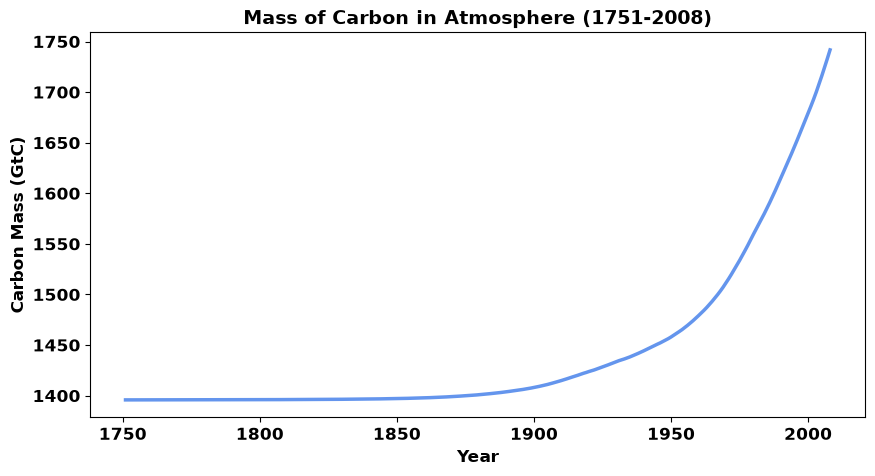

In [10]:
#mass of C in atmosphere vs time
plt.figure(figsize=(10,5))
plt.plot(t, M1, color='cornflowerblue', linewidth=2.5)
plt.xlabel('Year')
plt.ylabel('Carbon Mass (GtC)')
plt.title('Mass of Carbon in Atmosphere (1751-2008)')
plt.show()

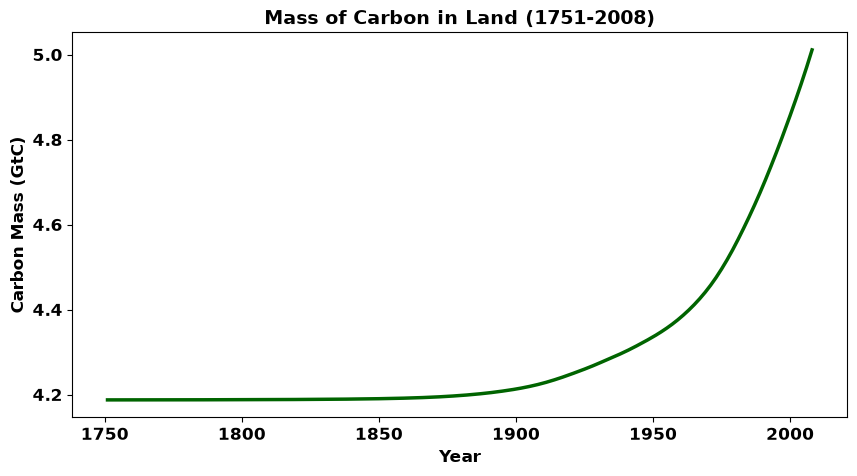

In [11]:
#mass of C in land vs. time
plt.figure(figsize=(10,5))
plt.plot(t, M2, color='darkgreen', linewidth=2.5)
plt.xlabel('Year')
plt.ylabel('Carbon Mass (GtC)')
plt.title('Mass of Carbon in Land (1751-2008)')
plt.show()

In [12]:
#change in mass of C in atmophere over time
dM1dt = np.diff(M1)/dt

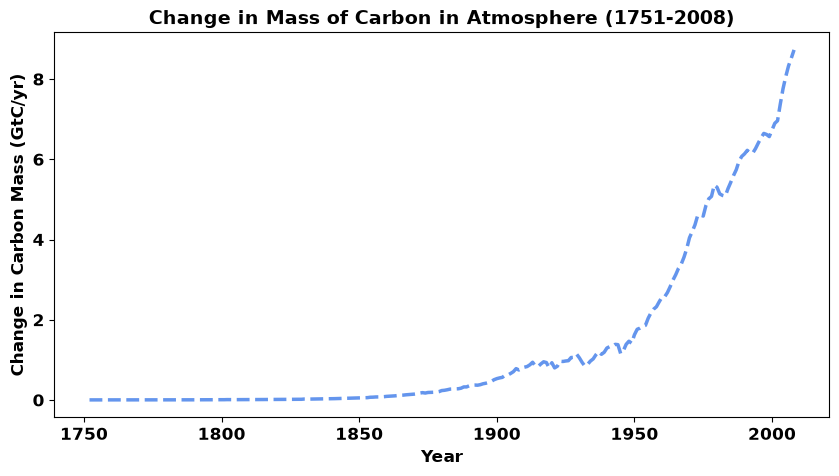

In [13]:
plt.figure(figsize=(10,5))
plt.plot(t[1:], dM1dt, color='cornflowerblue', linestyle='--', linewidth=2.5)
plt.xlabel('Year')
plt.ylabel('Change in Carbon Mass (GtC/yr)')
plt.title('Change in Mass of Carbon in Atmosphere (1751-2008)')
plt.show()

In [14]:
#change of mass of C in biosphere over time
dM2dt = np.diff(M2)/dt

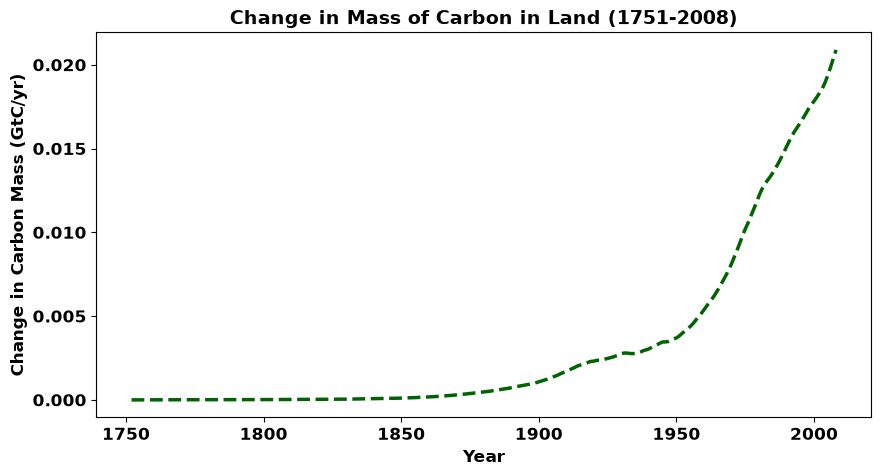

In [15]:
plt.figure(figsize=(10,5))
plt.plot(t[1:], dM2dt, color='darkgreen', linestyle='--', linewidth=2.5)
plt.xlabel('Year')
plt.ylabel('Change in Carbon Mass (GtC/yr)')
plt.title('Change in Mass of Carbon in Land (1751-2008)')
plt.show()

# Problem C

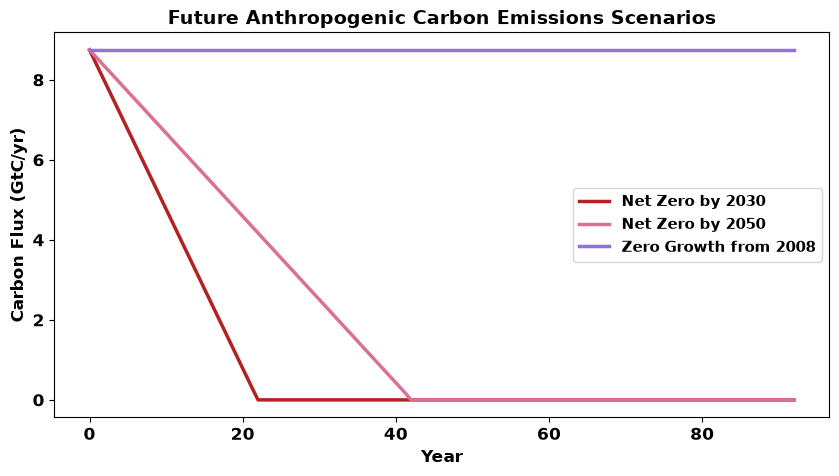

In [16]:
future_emissions_file = '/Users/lindsaysummers/Documents/Geos518/Earth-and-Environmental-Systems-Modeling/mod02_Finite-Difference-Box-Models/EmissionsMitigationScenarios.2008_2100.csv'
data = np.loadtxt(future_emissions_file, delimiter=',', skiprows=1)

# year = data[:, 0]
# column 2 = net zero by 2030
# column 3 = net zero by 2050
# column 4 = zero emissions growth
year = data[:, 0]
cflux_nz2030 = data[:, 1]
cflux_nz2050 = data[:, 2]
cflux_zeg = data[:, 3]

#plot each
plt.figure(figsize=(10,5))
plt.plot(cflux_nz2030, label='Net Zero by 2030', color='firebrick', linewidth=2.5)
plt.plot(cflux_nz2050, label='Net Zero by 2050', color='palevioletred', linewidth=2.5)
plt.plot(cflux_zeg, label='Zero Growth from 2008', color='mediumpurple', linewidth=2.5)
plt.xlabel('Year')
plt.ylabel('Carbon Flux (GtC/yr)')
plt.title('Future Anthropogenic Carbon Emissions Scenarios')
plt.legend()    
plt.show()

In [17]:
#starting with conditions as final conditions from 2008 run model for each future scenario

M1i = M1[-1]
M2i = M2[-1]

#make time array for future scenarios

#initial is 2008 final is 2030, 2050, and 2100
t_future = np.arange(2009.0, 2101.0, 1)
t_future.size

#interpolate the future emissions onto the model time array
cflux_nz2030_t = np.interp(t_future, year, cflux_nz2030)
cflux_nz2050_t = np.interp(t_future, year, cflux_nz2050)
cflux_zeg_t = np.interp(t_future, year, cflux_zeg)

#initialize the state arrays for each future scenario
M1_nz2030 = np.zeros((t_future.size,))
M2_nz2030 = np.zeros((t_future.size,))
M1_nz2050 = np.zeros((t_future.size,))
M2_nz2050 = np.zeros((t_future.size,))
M1_zeg = np.zeros((t_future.size,))
M2_zeg = np.zeros((t_future.size,))

#run model for each future scenario
for i in np.arange(t_future.size):
    if (i==0):
        M1_nz2030[i] = M1i
        M2_nz2030[i] = M2i
        M1_nz2050[i] = M1i
        M2_nz2050[i] = M2i
        M1_zeg[i] = M1i
        M2_zeg[i] = M2i
    else:
        dM1dt_nz2030 = k21 * M2_nz2030[i - 1] - k12 * M1_nz2030[i - 1] + cflux_nz2030_t[i]
        dM2dt_nz2030 = k12 * M1_nz2030[i - 1] - k21 * M2_nz2030[i - 1]

        dM1dt_nz2050 = k21 * M2_nz2050[i - 1] - k12 * M1_nz2050[i - 1] + cflux_nz2050_t[i]
        dM2dt_nz2050 = k12 * M1_nz2050[i - 1] - k21 * M2_nz2050[i - 1]

        dM1dt_zeg = k21 * M2_zeg[i - 1] - k12 * M1_zeg[i - 1] + cflux_zeg_t[i]
        dM2dt_zeg = k12 * M1_zeg[i - 1] - k21 * M2_zeg[i - 1]

        #update mass of carbon in atm and biosphere for each scenario
        M1_nz2030[i] = M1_nz2030[i-1] + dM1dt_nz2030*dt
        M2_nz2030[i] = M2_nz2030[i-1] + dM2dt_nz2030*dt

        M1_nz2050[i] = M1_nz2050[i-1] + dM1dt_nz2050*dt
        M2_nz2050[i] = M2_nz2050[i-1] + dM2dt_nz2050*dt

        M1_zeg[i] = M1_zeg[i-1] + dM1dt_zeg*dt
        M2_zeg[i] = M2_zeg[i-1] + dM2dt_zeg*dt

#print final mass of carbon in atmosphere and biosphere for each scenario
print('Final atmosphere mass in 2100 for Net Zero by 2030 =', M1_nz2030[-1], 'GtC')
print('Final biosphere mass in 2100 for Net Zero by 2030 =', M2_nz2030[-1], 'GtC')
print('Final atmosphere mass in 2100 for Net Zero by 2050 =', M1_nz2050[-1], 'GtC')
print('Final biosphere mass in 2100 for Net Zero by 2050 =', M2_nz2050[-1], 'GtC')
print('Final atmosphere mass in 2100 for Zero Emissions Growth =', M1_zeg[-1], 'GtC')
print('Final biosphere mass in 2100 for Zero Emissions Growth =', M2_zeg[-1], 'GtC')


Final atmosphere mass in 2100 for Net Zero by 2030 = 1824.7208931001142 GtC
Final biosphere mass in 2100 for Net Zero by 2030 = 5.474106899885667 GtC
Final atmosphere mass in 2100 for Net Zero by 2050 = 1912.0989812291084 GtC
Final biosphere mass in 2100 for Net Zero by 2050 = 5.73601877089064 GtC
Final atmosphere mass in 2100 for Zero Emissions Growth = 2535.5689748614345 GtC
Final biosphere mass in 2100 for Zero Emissions Growth = 7.345025138564804 GtC


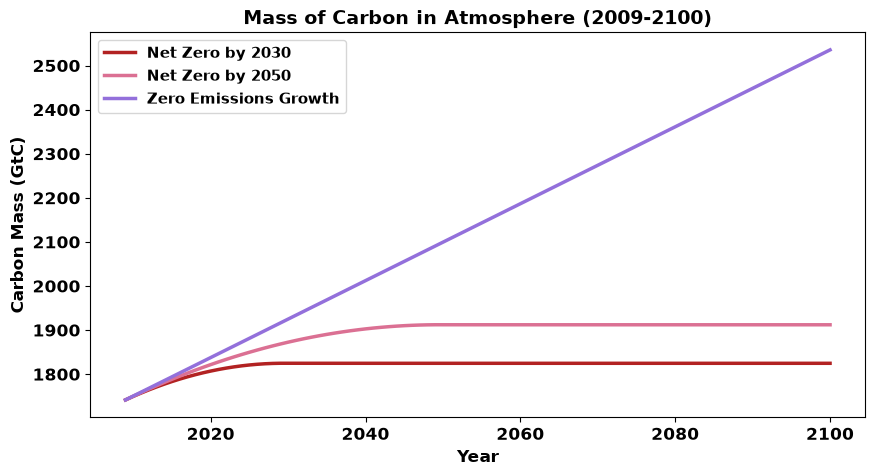

In [18]:
#mass of C in atmosphere vs time for all future scenarios
plt.figure(figsize=(10,5))
plt.plot(t_future, M1_nz2030, label='Net Zero by 2030', color='firebrick', linewidth=2.5)
plt.plot(t_future, M1_nz2050, label='Net Zero by 2050', color='palevioletred', linewidth=2.5)
plt.plot(t_future, M1_zeg, label='Zero Emissions Growth', color='mediumpurple', linewidth=2.5)
plt.xlabel('Year')
plt.ylabel('Carbon Mass (GtC)')
plt.title('Mass of Carbon in Atmosphere (2009-2100)')
plt.legend()
plt.show()

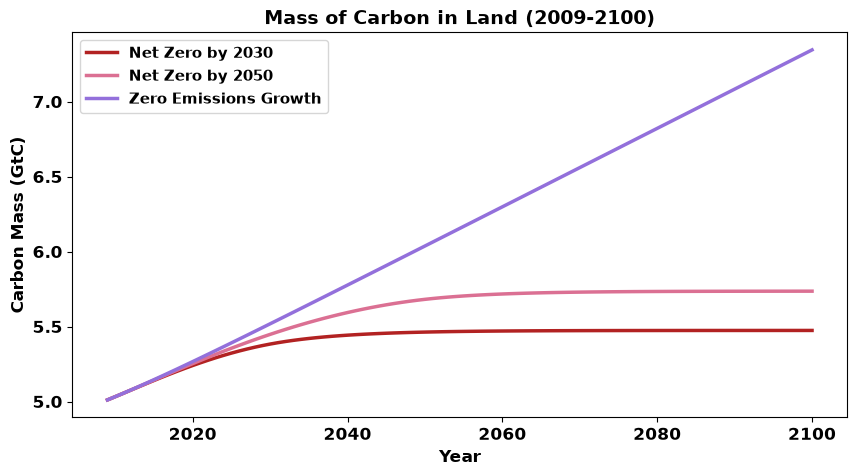

In [19]:
#mass of C in land vs. time for all future scenarios
plt.figure(figsize=(10,5))
plt.plot(t_future, M2_nz2030, label='Net Zero by 2030', color='firebrick', linewidth=2.5)
plt.plot(t_future, M2_nz2050, label='Net Zero by 2050', color='palevioletred', linewidth=2.5)
plt.plot(t_future, M2_zeg, label='Zero Emissions Growth', color='mediumpurple', linewidth=2.5)
plt.xlabel('Year')
plt.ylabel('Carbon Mass (GtC)')
plt.title('Mass of Carbon in Land (2009-2100)')
plt.legend()
plt.show()

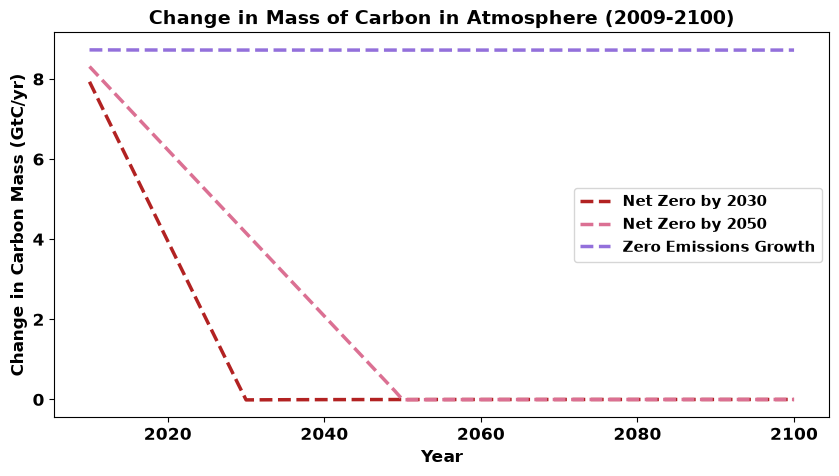

In [20]:
#change in mass of C in atmosphere over time

#change in mass of C in atmosphere over time for all future scenarios
dM1dt_nz2030 = np.diff(M1_nz2030)/dt
dM1dt_nz2050 = np.diff(M1_nz2050)/dt
dM1dt_zeg = np.diff(M1_zeg)/dt

plt.figure(figsize=(10,5))
plt.plot(t_future[1:], dM1dt_nz2030, label='Net Zero by 2030', color='firebrick', linewidth=2.5, linestyle='--')
plt.plot(t_future[1:], dM1dt_nz2050, label='Net Zero by 2050', color='palevioletred', linewidth=2.5, linestyle='--')
plt.plot(t_future[1:], dM1dt_zeg, label='Zero Emissions Growth', color='mediumpurple', linewidth=2.5, linestyle='--')
plt.xlabel('Year')
plt.ylabel('Change in Carbon Mass (GtC/yr)')
plt.title('Change in Mass of Carbon in Atmosphere (2009-2100)')
plt.legend()
plt.show()

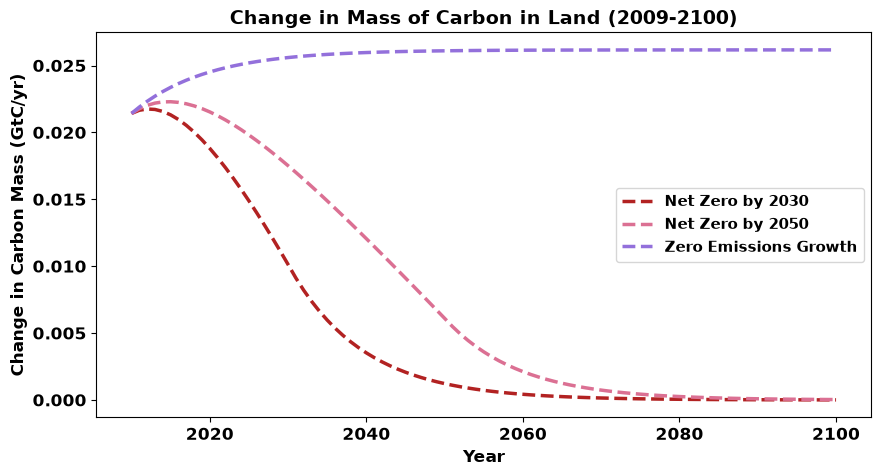

In [21]:
#change in mass of C in biosphere over time

#change in mass of C in biosphere over time for all future scenarios
dM2dt_nz2030 = np.diff(M2_nz2030)/dt
dM2dt_nz2050 = np.diff(M2_nz2050)/dt
dM2dt_zeg = np.diff(M2_zeg)/dt

plt.figure(figsize=(10,5))
plt.plot(t_future[1:], dM2dt_nz2030, label='Net Zero by 2030', color='firebrick', linewidth=2.5, linestyle='--')
plt.plot(t_future[1:], dM2dt_nz2050, label='Net Zero by 2050', color='palevioletred', linewidth=2.5, linestyle='--')
plt.plot(t_future[1:], dM2dt_zeg, label='Zero Emissions Growth', color='mediumpurple', linewidth=2.5, linestyle='--')
plt.xlabel('Year')
plt.ylabel('Change in Carbon Mass (GtC/yr)')
plt.title('Change in Mass of Carbon in Land (2009-2100)')
plt.legend()
plt.show()

## 2. Assignment Tasks

For all plots, label all axes and provide units.

__Problem A: Modify and rerun the model__

1. Modify the model so that the photosynthesis flux includes the mass of carbon in the land (i.e., $M_2$). Use the following parameters:

  * $M_1^0$ = 1100.0 
  * $M_2^0$ = 300.0 
  * $k_{12}$ = 0.0003 
  * $k_{21}$ = 0.1  

2. Repeat the "unforced" (i.e., no anthropogenic emissions) simulation above, but run the model for `t = 100` years with a daily time step (i.e., `dt = 1/365`)
3. Use the `print()` command to print out the value of $M_1$ and $M_2$ at the end of the simulation

__Problem B: Examine impacts of human emissions__

1. Load the anthropogenic emissions data for 1751-2008 (see numpy `np.loadtxt()` command usage [here](https://numpy.org/doc/stable/reference/generated/numpy.loadtxt.html)). Note that the data is in a comma separated variable file (named `AnthropogenicEmissions.1751_2008.csv`) with one header row.
2. Plot the anthropogenic emissions data  
3. Starting from the initial conditions ($M_1^0$ and $M_2^0$) corresponding to the final conditions noted in part __A(3)__ above, simulate the response of the carbon system to the anthropogenic emissions from 1751 to 2008 by adding an appropriate source term in the system of equations. Create the following plots:

  * Mass of C in the atmosphere versus time 
  * Mass of C in the land versus time 
  * The change in mass of C in the atmosphere vs time 
  * The change in mass of C in the biosphere vs time 
    
4. Use the `print()` command to print out the value of $M_1$ and $M_2$ at the end of the simulation in 2008.

__Problem C: Examine the effects of mitigation__

1. Load the alternative emission scenarios contained in the file `.csv`, which represent three pathways to net zero emissions: (a) net zero emissions by the year 2030 (column 2), (c) net zero emissions by 2050 (column 3), and zero emissions growth (i.e., constant emissions) starting in 2008 (column 4).
2. Starting from the initial conditions ($M_1^0$ and $M_2^0$) corresponding to the final conditions noted in part __B(4)__ above, run the model three times, one for each scenario. Create the following plots: 

  * Mass of C in the atmosphere versus time (all three scenarios on one plot)
  * Mass of C in the land versus time (all three scenarios on one plot)
  * The change in mass of C in the atmosphere vs time 
  * The change in mass of C in the biosphere vs time 


In [22]:
# future_emissions_file = 'EmissionsMitigationScenarios.csv'

# data = np.loadtxt()
# year = data[:,0]
# cflux_nz2030 = data[:,1]
# cflux_nz2050 = data[:,2]
# cflux_zeg = data[:,3]